In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns


In [2]:
df=pd.read_csv('Algerian_forest_fires_cleaned_dataset.csv')

In [3]:
df.head()

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,1,6,2012,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,0
1,2,6,2012,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,not fire,0
2,3,6,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0
3,4,6,2012,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,not fire,0
4,5,6,2012,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,not fire,0


In [4]:
df.columns

Index(['day', 'month', 'year', 'Temperature', 'RH', 'Ws', 'Rain', 'FFMC',
       'DMC', 'DC', 'ISI', 'BUI', 'FWI', 'Classes', 'Region'],
      dtype='object')

In [5]:
df.drop(['day','month','year'],axis=1,inplace=True)

In [6]:
df.head()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,0
1,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,not fire,0
2,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0
3,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,not fire,0
4,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,not fire,0


In [7]:
df['Classes']=df['Classes'].str.strip()

In [8]:
## Encoding
df['Classes']=np.where(df['Classes'].str.contains('not fire'),0,1)

In [9]:
df.head()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,0,0
1,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,0,0
2,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,0,0
3,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,0,0
4,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,0,0


In [10]:
# Independent and dependent features
X=df.drop('FWI',axis=1)
y=df['FWI']

In [11]:
X.head()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,Classes,Region
0,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0,0
1,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0,0
2,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0,0
3,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0,0
4,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0,0


In [12]:
X.shape,y.shape

((243, 11), (243,))

In [13]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.23,random_state=42)


In [14]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((187, 11), (56, 11), (187,), (56,))

In [15]:
# Feature selection based on correlation
X_train.corr()


,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,Classes,Region
Temperature,1.000000,-0.659483,-0.306572,-0.314737,0.694140,0.496883,0.387493,0.628191,0.471465,0.537194,0.260602
RH,-0.659483,1.000000,0.228985,0.239121,-0.651443,-0.416586,-0.236723,-0.715473,-0.363677,-0.453090,-0.397607
Ws,-0.306572,0.228985,1.000000,0.250321,-0.192252,-0.003038,0.093646,-0.026523,0.032284,-0.084103,-0.202205
Rain,-0.314737,0.239121,0.250321,1.000000,-0.546686,-0.290551,-0.302913,-0.348777,-0.301478,-0.376281,-0.060495
FFMC,0.694140,-0.651443,-0.192252,-0.546686,1.000000,0.618155,0.519789,0.750171,0.603542,0.781614,0.257461
DMC,0.496883,-0.416586,-0.003038,-0.290551,0.618155,1.000000,0.869093,0.687483,0.983205,0.611110,0.205861
DC,0.387493,-0.236723,0.093646,-0.302913,0.519789,0.869093,1.000000,0.515683,0.942660,0.536699,-0.067582
ISI,0.628191,-0.715473,-0.026523,-0.348777,0.750171,0.687483,0.515683,1.000000,0.645517,0.740540,0.293176
BUI,0.471465,-0.363677,0.032284,-0.301478,0.603542,0.983205,0.942660,0.645517,1.000000,0.605102,0.107739
Classes,0.537194,-0.453090,-0.084103,-0.376281,0.781614,0.611110,0.536699,0.740540,0.605102,1.000000,0.197333


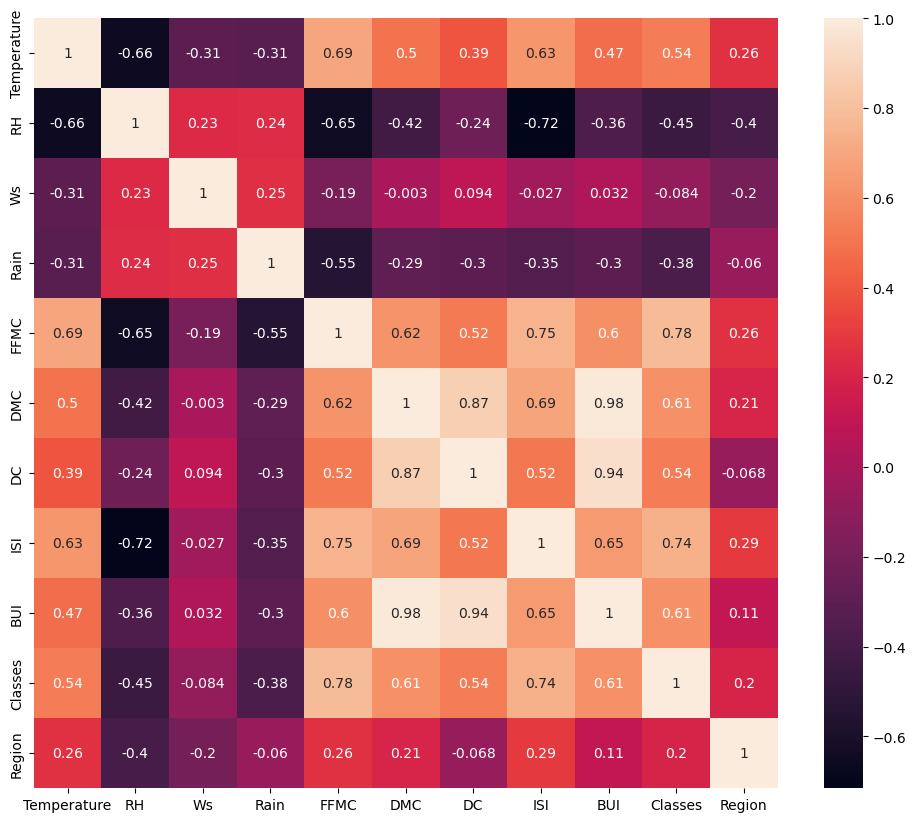

In [16]:
## Check for multicollinearity using heatmap
plt.figure(figsize=(12,10))
corr=X_train.corr()
sns.heatmap(corr,annot=True)
plt.show()

In [17]:
def correlation(dataset,threshold):
    col_corr=set()
    corr_matrix=dataset.corr()
    for i in range(len(corr_matrix.columns)):
        for j in range(i):
            if abs(corr_matrix.iloc[i,j])>threshold:
                colname=corr_matrix.columns[i]
                col_corr.add(colname)
    return col_corr

In [18]:
corr_features=correlation(X_train,0.85)

In [19]:
corr_features

{'BUI', 'DC'}

In [20]:
X_train.drop(corr_features,axis=1,inplace=True)
X_test.drop(corr_features,axis=1,inplace=True)
X_train.shape,X_test.shape


((187, 9), (56, 9))

## Feature scaling and standardization


In [21]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

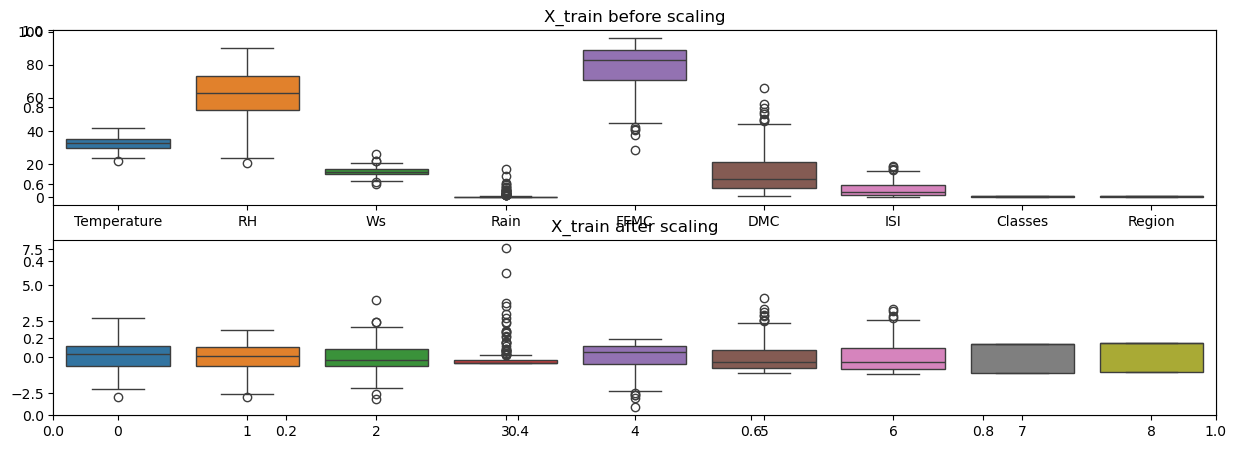

In [23]:
plt.subplots(figsize=(15,5))
plt.subplot(2,1,1)
sns.boxplot(data=X_train)
plt.title('X_train before scaling')
plt.subplot(2,1,2)
sns.boxplot(data=X_train_scaled)
plt.title('X_train after scaling')
plt.show()

## Linear Regression Model

Mean Squared error:  0.7275050957513091
Root Mean Squared error:  0.8529390926386884
Mean Absolute error:  0.5759699915797645
R2 Score:  0.9841721098920352


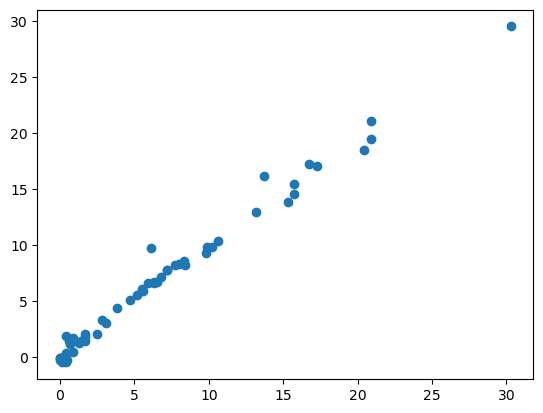

In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
model=LinearRegression()
model.fit(X_train_scaled,y_train)
temppred=model.predict(X_test_scaled)
mse=mean_squared_error(y_test,temppred)
rmse=np.sqrt(mse)
mae=mean_absolute_error(y_test,temppred)
score=r2_score(y_test,temppred)
print("Mean Squared error: ",mse)
print("Root Mean Squared error: ",rmse)
print("Mean Absolute error: ",mae)
print("R2 Score: ",score)
plt.scatter(y_test,temppred)
plt.show()




## Lasso Regression


Mean Squared error:  2.3341693498909986
Root Mean Squared error:  1.5277988577986954
Mean Absolute error:  1.146413671926142
R2 Score:  0.9492168835940585


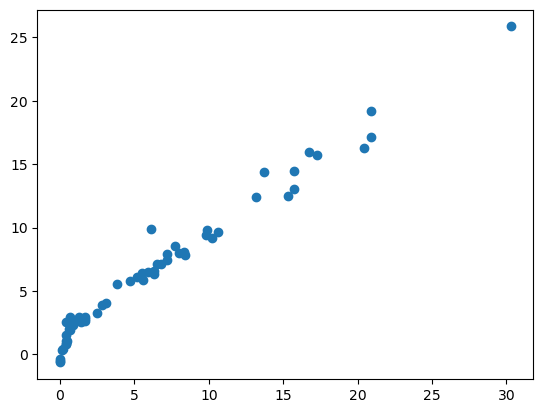

In [28]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
lasso=Lasso()
lasso.fit(X_train_scaled,y_train)
temppred1=lasso.predict(X_test_scaled)
mse=mean_squared_error(y_test,temppred1)
rmse=np.sqrt(mse)
mae=mean_absolute_error(y_test,temppred1)
score=r2_score(y_test,temppred1)
print("Mean Squared error: ",mse)
print("Root Mean Squared error: ",rmse)
print("Mean Absolute error: ",mae)
print("R2 Score: ",score)
plt.scatter(y_test,temppred1)
plt.show()



## Cross validation Lasso

In [26]:
from sklearn.linear_model import LassoCV
lassocv=LassoCV(cv=5)
lassocv.fit(X_train_scaled,y_train)

LassoCV(cv=5)

Mean Squared error:  0.8476887180782724
Root Mean Squared error:  0.9207001238613322
Mean Absolute error:  0.6528798577089786
R2 Score:  0.9815573472215362


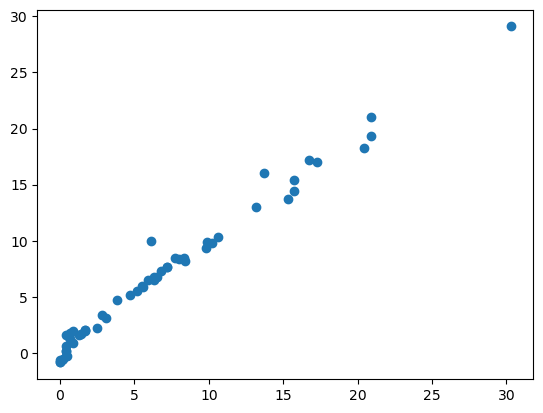

In [29]:
temppred2=lassocv.predict(X_test_scaled)
mse=mean_squared_error(y_test,temppred2)
rmse=np.sqrt(mse)
mae=mean_absolute_error(y_test,temppred2)
score=r2_score(y_test,temppred2)
print("Mean Squared error: ",mse)
print("Root Mean Squared error: ",rmse)
print("Mean Absolute error: ",mae)
print("R2 Score: ",score)
plt.scatter(y_test,temppred2)
plt.show()

## Ridge Regression

Mean Squared error:  0.7505446503749645
Root Mean Squared error:  0.866339800756588
Mean Absolute error:  0.5962439517488152
R2 Score:  0.9836708521814717


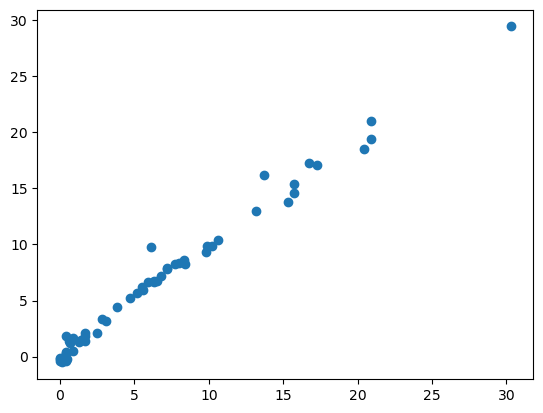

In [31]:
from sklearn.linear_model import Ridge
ridge=Ridge()
ridge.fit(X_train_scaled,y_train)
temppred3=ridge.predict(X_test_scaled)
mse=mean_squared_error(y_test,temppred3)
rmse=np.sqrt(mse)
mae=mean_absolute_error(y_test,temppred3)
score=r2_score(y_test,temppred3)
print("Mean Squared error: ",mse)
print("Root Mean Squared error: ",rmse)
print("Mean Absolute error: ",mae)
print("R2 Score: ",score)
plt.scatter(y_test,temppred3)
plt.show()

Mean Squared error:  0.7505446503749645
Root Mean Squared error:  0.866339800756588
Mean Absolute error:  0.5962439517488152
R2 Score:  0.9836708521814717


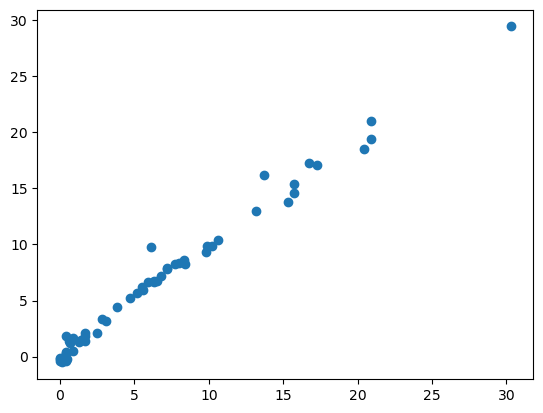

In [33]:
from sklearn.linear_model import RidgeCV
ridgecv=RidgeCV(cv=5)
ridgecv.fit(X_train_scaled,y_train)
temppred4=ridgecv.predict(X_test_scaled)
mse=mean_squared_error(y_test,temppred4)
rmse=np.sqrt(mse)
mae=mean_absolute_error(y_test,temppred4)
score=r2_score(y_test,temppred4)
print("Mean Squared error: ",mse)
print("Root Mean Squared error: ",rmse)
print("Mean Absolute error: ",mae)
print("R2 Score: ",score)
plt.scatter(y_test,temppred4)
plt.show()

Mean Squared error:  5.634156214358646
Root Mean Squared error:  2.3736377597179072
Mean Absolute error:  1.8731479970853953
R2 Score:  0.8774210573468482


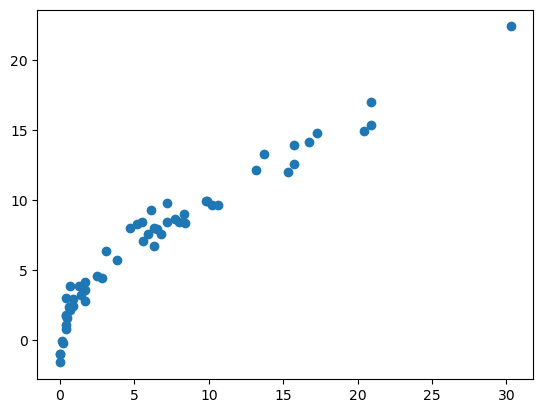

In [34]:
from sklearn.linear_model import ElasticNet
elastic=ElasticNet()
elastic.fit(X_train_scaled,y_train)
temppred5=elastic.predict(X_test_scaled)
mse=mean_squared_error(y_test,temppred5)
rmse=np.sqrt(mse)
mae=mean_absolute_error(y_test,temppred5)
score=r2_score(y_test,temppred5)
print("Mean Squared error: ",mse)
print("Root Mean Squared error: ",rmse)
print("Mean Absolute error: ",mae)
print("R2 Score: ",score)
plt.scatter(y_test,temppred5)
plt.show()

Mean Squared error:  0.8705412056369282
Root Mean Squared error:  0.9330279768779327
Mean Absolute error:  0.6829342750565518
R2 Score:  0.9810601594164137


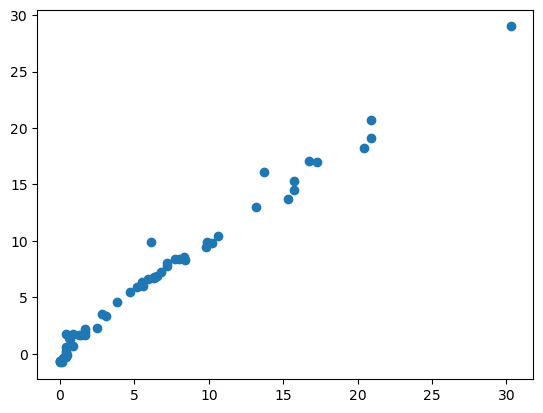

In [35]:
from sklearn.linear_model import ElasticNetCV
elasticcv=ElasticNetCV()
elasticcv.fit(X_train_scaled,y_train)
temppred6=elasticcv.predict(X_test_scaled)
mse=mean_squared_error(y_test,temppred6)
rmse=np.sqrt(mse)
mae=mean_absolute_error(y_test,temppred6)
score=r2_score(y_test,temppred6)
print("Mean Squared error: ",mse)
print("Root Mean Squared error: ",rmse)
print("Mean Absolute error: ",mae)
print("R2 Score: ",score)
plt.scatter(y_test,temppred6)
plt.show()

## Pickle the machine learning models,preprocessing model standardscaler

In [36]:
scaler

StandardScaler()

In [37]:
Ridge

sklearn.linear_model._ridge.Ridge

In [38]:
import pickle
pickle.dump(scaler,open('scaler.pkl','wb'))
pickle.dump(ridge,open('ridge.pkl','wb'))
